In [4]:
#Import Dependencies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, LabelEncoder


In [5]:
df = pd.read_csv("Sample_AQI_Data_Pune_Central.csv")

# Basic Info
print("🔹 Dataset Shape:", df.shape)
print("\n🔹 Columns:", df.columns.tolist())
print("\n🔹 Missing Values:\n", df.isnull().sum())

🔹 Dataset Shape: (150, 12)

🔹 Columns: ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3', 'Temperature', 'Humidity', 'WindSpeed', 'Region', 'AQI', 'AQI_Category']

🔹 Missing Values:
 PM2.5           0
PM10            0
NO2             0
SO2             0
CO              0
O3              0
Temperature     0
Humidity        0
WindSpeed       0
Region          0
AQI             0
AQI_Category    0
dtype: int64


In [6]:
# Region is categorical, and AQI_Category is target
le = LabelEncoder()
df["Region"] = le.fit_transform(df["Region"])
df["AQI_Category"] = le.fit_transform(df["AQI_Category"])

In [7]:
X = df.drop(["AQI", "AQI_Category"], axis=1)
y = df["AQI_Category"]

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [10]:
print("\n✅ Preprocessing Complete")
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)



✅ Preprocessing Complete
Training Data Shape: (120, 10)
Testing Data Shape: (30, 10)


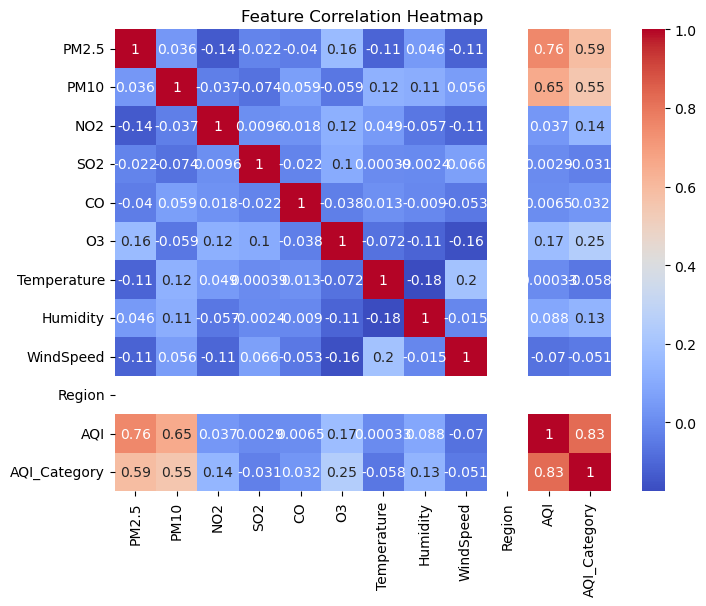

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report




In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,       # number of trees
    criterion="entropy",    # can also use "gini"
    max_depth=None,
    random_state=42
)

In [18]:
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)


acc = accuracy_score(y_test, y_pred_rf)
prec = precision_score(y_test, y_pred_rf, average='weighted')
rec = recall_score(y_test, y_pred_rf, average='weighted')
f1 = f1_score(y_test, y_pred_rf, average='weighted')

print("📊 Random Forest Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))
print("Unique labels in y_test:", np.unique(y_test))
print("Unique labels predicted:", np.unique(y_pred_rf))


📊 Random Forest Model Evaluation:
Accuracy:  0.833
Precision: 0.772
Recall:    0.833
F1-Score:  0.799

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.75      0.67      0.71         9
           2       0.86      1.00      0.93        19

    accuracy                           0.83        30
   macro avg       0.54      0.56      0.54        30
weighted avg       0.77      0.83      0.80        30

Unique labels in y_test: [0 1 2]
Unique labels predicted: [1 2]


c:\Users\advai\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


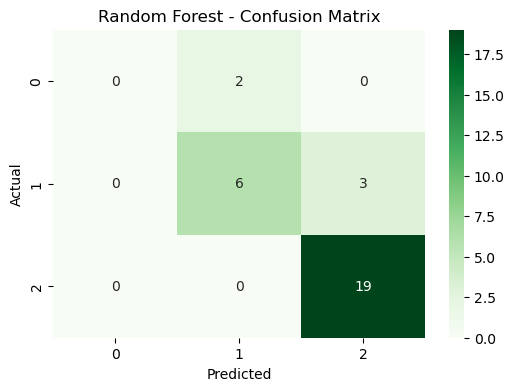

In [19]:
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Greens", fmt='g')
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

C:\Users\advai\AppData\Local\Temp\ipykernel_25396\694074173.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Feature", data=feat_df, palette="viridis")


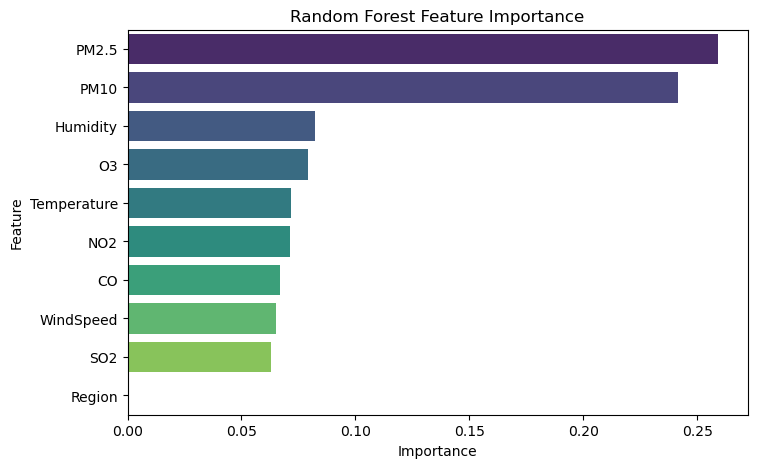

In [20]:
importances = rf_model.feature_importances_
feature_names = X.columns  # original feature names
feat_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
feat_df = feat_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Importance", y="Feature", data=feat_df, palette="viridis")
plt.title("Random Forest Feature Importance")
plt.show()

📊 Logistic Regression Model Evaluation:
Accuracy:  0.933
Precision: 0.879
Recall:    0.933
F1-Score:  0.903

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.82      1.00      0.90         9
           2       1.00      1.00      1.00        19

    accuracy                           0.93        30
   macro avg       0.61      0.67      0.63        30
weighted avg       0.88      0.93      0.90        30



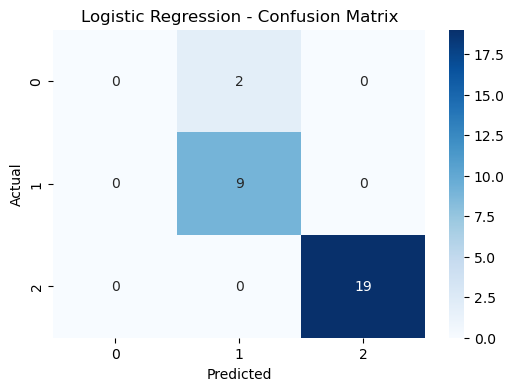

C:\Users\advai\AppData\Local\Temp\ipykernel_25396\744743703.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient Magnitude", y="Feature", data=feat_df, palette="coolwarm")


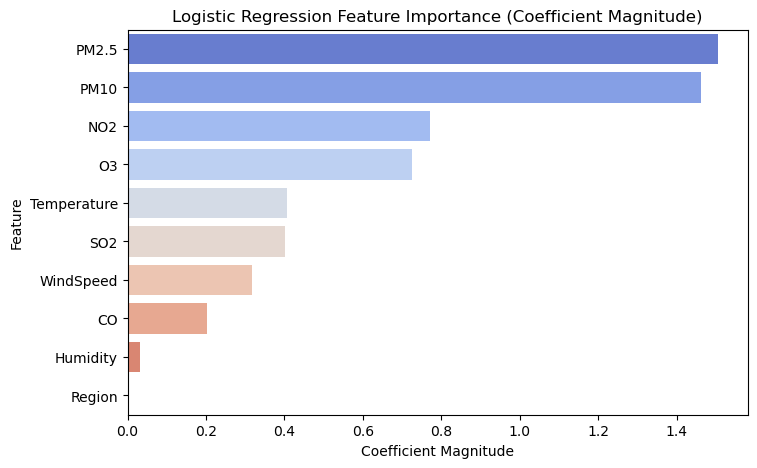

In [21]:
# LOGISTIC REGRESSION - MODEL TRAINING & EVALUATION
# ==========================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ⿡ Initialize Logistic Regression Model
log_reg = LogisticRegression(
    solver='lbfgs',      # common solver (you can try 'liblinear' for small datasets)
    max_iter=1000,       # increased to ensure convergence
    random_state=42
)

# ⿢ Train the Model
log_reg.fit(X_train, y_train)

# ⿣ Make Predictions
y_pred_lr = log_reg.predict(X_test)

# ⿤ Evaluate Performance
acc = accuracy_score(y_test, y_pred_lr)
prec = precision_score(y_test, y_pred_lr, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_lr, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_lr, average='weighted', zero_division=0)

print("📊 Logistic Regression Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# ⿥ Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt='g')
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ⿦ Optional: Feature Importance Visualization
# (Coefficients represent feature importance in Logistic Regression)
import numpy as np
coef = np.abs(log_reg.coef_[0])  # take absolute value for importance
feature_names = X.columns

feat_df = pd.DataFrame({"Feature": feature_names, "Coefficient Magnitude": coef})
feat_df = feat_df.sort_values(by="Coefficient Magnitude", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Coefficient Magnitude", y="Feature", data=feat_df, palette="coolwarm")
plt.title("Logistic Regression Feature Importance (Coefficient Magnitude)")
plt.show()


📊 Gaussian Naive Bayes Model Evaluation:
Accuracy:  0.833
Precision: 0.780
Recall:    0.833
F1-Score:  0.806

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.70      0.78      0.74         9
           2       0.90      0.95      0.92        19

    accuracy                           0.83        30
   macro avg       0.53      0.58      0.55        30
weighted avg       0.78      0.83      0.81        30



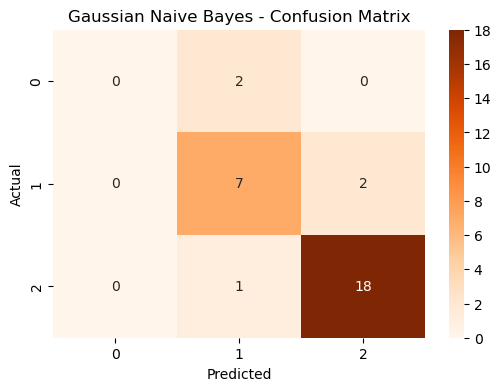

In [24]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ⿡ Initialize Gaussian Naive Bayes Model
nb_model = GaussianNB()

# ⿢ Train the Model
nb_model.fit(X_train, y_train)

# ⿣ Make Predictions
y_pred_nb = nb_model.predict(X_test)

# ⿤ Evaluate Performance
acc = accuracy_score(y_test, y_pred_nb)
prec = precision_score(y_test, y_pred_nb, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_nb, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_nb, average='weighted', zero_division=0)

print("📊 Gaussian Naive Bayes Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

# ⿥ Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Oranges", fmt='g')
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


📊 Linear SVC Model Evaluation:
Accuracy:  0.933
Precision: 0.879
Recall:    0.933
F1-Score:  0.903

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.82      1.00      0.90         9
           2       1.00      1.00      1.00        19

    accuracy                           0.93        30
   macro avg       0.61      0.67      0.63        30
weighted avg       0.88      0.93      0.90        30



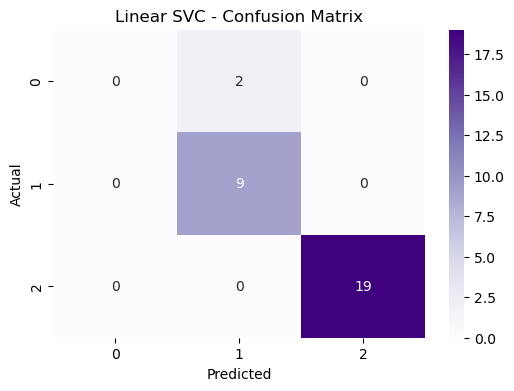

C:\Users\advai\AppData\Local\Temp\ipykernel_25396\1620613202.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient Magnitude", y="Feature", data=feat_df, palette="mako")


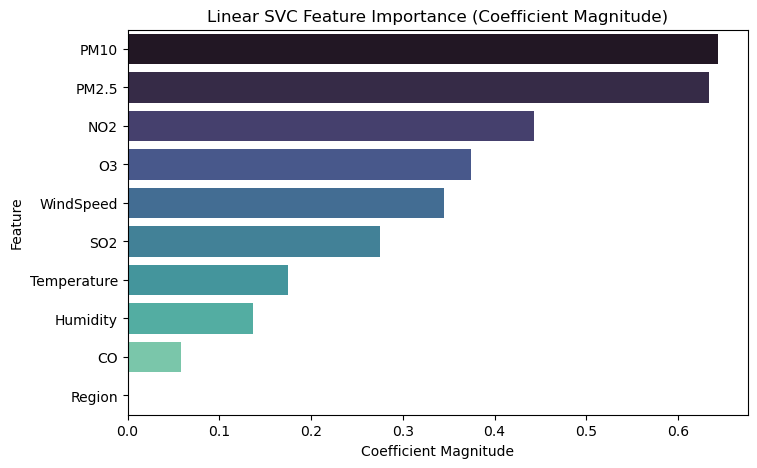

In [25]:
# LINEAR SVM (LinearSVC) - MODEL TRAINING & EVALUATION
# ==========================================================

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# ⿡ Initialize Linear SVC Model
svc_model = LinearSVC(
    penalty='l2',          # standard regularization
    loss='squared_hinge',  # default loss for LinearSVC
    max_iter=5000,         # ensure convergence
    random_state=42
)

# ⿢ Train the Model
svc_model.fit(X_train, y_train)

# ⿣ Make Predictions
y_pred_svc = svc_model.predict(X_test)

# ⿤ Evaluate Performance
acc = accuracy_score(y_test, y_pred_svc)
prec = precision_score(y_test, y_pred_svc, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_svc, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_svc, average='weighted', zero_division=0)

print("📊 Linear SVC Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_svc, zero_division=0))

# ⿥ Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred_svc)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Purples", fmt='g')
plt.title("Linear SVC - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ⿦ Optional: Feature Importance Visualization
# In LinearSVC, coefficients represent feature weights
coef = np.abs(svc_model.coef_[0])  # take absolute values for importance
feature_names = X.columns

feat_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient Magnitude": coef
}).sort_values(by="Coefficient Magnitude", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Coefficient Magnitude", y="Feature", data=feat_df, palette="mako")
plt.title("Linear SVC Feature Importance (Coefficient Magnitude)")
plt.show()


📊 Gradient Boosting Model Evaluation:
Accuracy:  0.900
Precision: 0.925
Recall:    0.900
F1-Score:  0.900

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.75      1.00      0.86         9
           2       1.00      0.89      0.94        19

    accuracy                           0.90        30
   macro avg       0.92      0.80      0.82        30
weighted avg       0.93      0.90      0.90        30



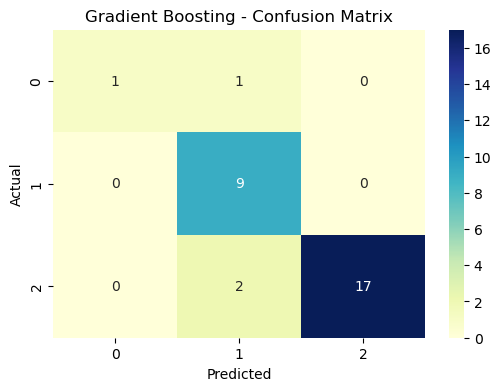

C:\Users\advai\AppData\Local\Temp\ipykernel_25396\640276482.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Feature", data=feat_df, palette="crest")


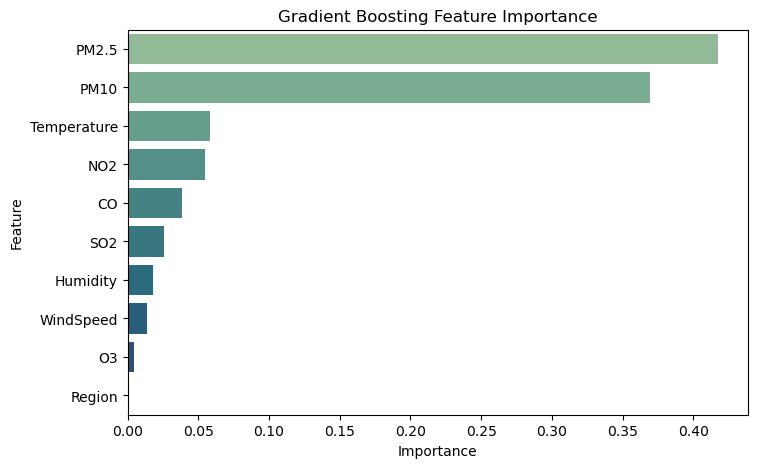

In [26]:
# GRADIENT BOOSTING - MODEL TRAINING & EVALUATION
# ==========================================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# ⿡ Initialize Gradient Boosting Model
gb_model = GradientBoostingClassifier(
    n_estimators=100,       # number of boosting stages (trees)
    learning_rate=0.1,      # controls contribution of each tree
    max_depth=3,            # depth of individual trees
    random_state=42
)

# ⿢ Train the Model
gb_model.fit(X_train, y_train)

# ⿣ Make Predictions
y_pred_gb = gb_model.predict(X_test)

# ⿤ Evaluate Performance
acc = accuracy_score(y_test, y_pred_gb)
prec = precision_score(y_test, y_pred_gb, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_gb, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_gb, average='weighted', zero_division=0)

print("📊 Gradient Boosting Model Evaluation:")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-Score:  {f1:.3f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_gb, zero_division=0))

# ⿥ Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="YlGnBu", fmt='g')
plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ⿦ Optional: Feature Importance Visualization
importances = gb_model.feature_importances_
feature_names = X.columns

feat_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x="Importance", y="Feature", data=feat_df, palette="crest")
plt.title("Gradient Boosting Feature Importance")
plt.show()
